In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/student-mat.csv', sep=';')

# Display first 5 rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (395, 33)

Columns:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [3]:
# Create PASS/FAIL target column

df['Pass_Fail'] = (df['G3'] >= 10).astype(int)

# Display first 10 rows
df[['studytime', 'absences', 'G1', 'G2', 'G3', 'Pass_Fail']].head(10)

,studytime,absences,G1,G2,G3,Pass_Fail
0,2,6,5,6,6,0
1,2,4,5,5,6,0
2,2,10,7,8,10,1
3,3,2,15,14,15,1
4,2,4,6,10,10,1
5,2,10,15,15,15,1
6,2,0,12,12,11,1
7,2,6,6,5,6,0
8,2,0,16,18,19,1
9,2,0,14,15,15,1


In [4]:
# Count PASS and FAIL students

print(df['Pass_Fail'].value_counts())

# Display percentage
print("\nPercentage:")
print(df['Pass_Fail'].value_counts(normalize=True) * 100)

Pass_Fail
1    265
0    130
Name: count, dtype: int64

Percentage:
Pass_Fail
1    67.088608
0    32.911392
Name: proportion, dtype: float64


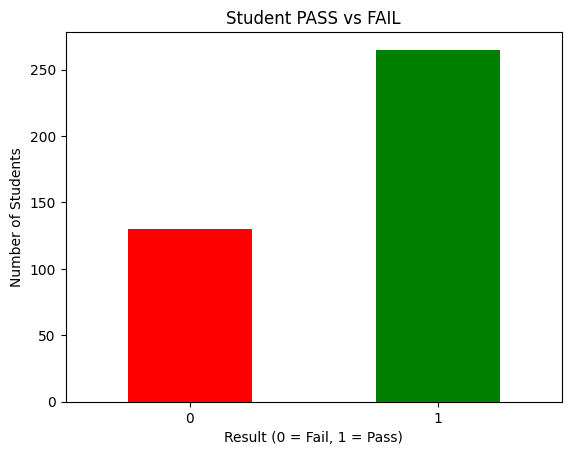

In [5]:
import matplotlib.pyplot as plt

df['Pass_Fail'].value_counts().sort_index().plot(
    kind='bar',
    color=['red', 'green']
)

plt.title('Student PASS vs FAIL')
plt.xlabel('Result (0 = Fail, 1 = Pass)')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.show()

In [6]:
# Select input features
X = df[['studytime', 'absences', 'G1', 'G2']]

# Select target column
y = df['Pass_Fail']

# Display input features
print("Input Features:")
print(X.head())

# Display target
print("\nTarget:")
print(y.head())

Input Features:
   studytime  absences  G1  G2
0          2         6   5   6
1          2         4   5   5
2          2        10   7   8
3          3         2  15  14
4          2         4   6  10

Target:
0    0
1    0
2    1
3    1
4    1
Name: Pass_Fail, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 4)
Testing data: (79, 4)


In [8]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

print("\nTesting data after scaling:")
print(X_test_scaled[:5])

Training data after scaling:
[[ 2.38673473 -0.68870507 -1.20505021 -0.46592369]
 [-1.26265966  0.05745768  2.15941126  1.92162041]
 [-1.26265966 -0.68870507 -0.89919007 -2.85346779]
 [-1.26265966 -0.68870507 -1.81677047 -2.85346779]
 [-1.26265966  0.18181814 -1.51091034 -1.5270544 ]]

Testing data after scaling:
[[-0.04619487  0.3061786   0.93597072  0.32992434]
 [-0.04619487  1.30106227 -0.59332994 -0.73120637]
 [-1.26265966  1.79850411  0.63011059  0.32992434]
 [ 1.17026993 -0.68870507  0.01839032  0.06464167]
 [-0.04619487 -0.68870507  1.54769099  1.65633773]]


In [10]:
from sklearn.linear_model import LogisticRegression

# Create model
model = LogisticRegression()

# Train model
model.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [11]:
# Predict student results
y_pred = model.predict(X_test_scaled)

print("Predicted Results:")
print(y_pred[:10])

print("\nActual Results:")
print(y_test.values[:10])

Predicted Results:
[1 0 1 1 1 1 1 0 1 1]

Actual Results:
[1 0 1 1 1 1 1 0 1 1]


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 88.60759493670885 %


In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Fail', 'Pass']
))

              precision    recall  f1-score   support

        Fail       0.79      0.88      0.84        26
        Pass       0.94      0.89      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.89      0.87        79
weighted avg       0.89      0.89      0.89        79



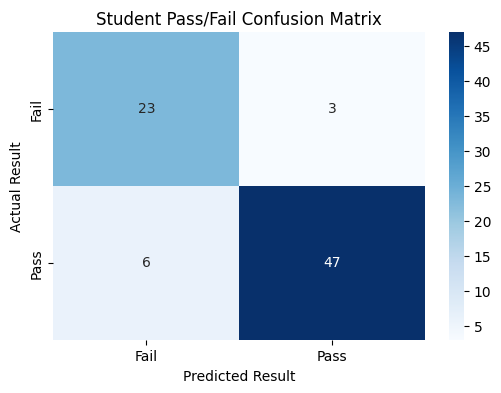

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted Result')
plt.ylabel('Actual Result')
plt.title('Student Pass/Fail Confusion Matrix')

plt.show()

In [15]:
import joblib

# Save model and scaler together
joblib.dump(
    {
        'model': model,
        'scaler': scaler,
        'features': ['studytime', 'absences', 'G1', 'G2']
    },
    'student_pass_fail_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [16]:
from google.colab import files

files.download('student_pass_fail_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import joblib
import pandas as pd

# Load saved model
saved_data = joblib.load('student_pass_fail_model.pkl')

loaded_model = saved_data['model']
loaded_scaler = saved_data['scaler']

# Student information with column names
student = pd.DataFrame(
    [[3, 2, 15, 14]],
    columns=['studytime', 'absences', 'G1', 'G2']
)

# Scale student data
student_scaled = loaded_scaler.transform(student)

# Predict
prediction = loaded_model.predict(student_scaled)

if prediction[0] == 1:
    print("Student Result: PASS")
else:
    print("Student Result: FAIL")

Student Result: PASS
